# Hamiltonian simulation on a quantum computer, step by step

[![Run on Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/ENCCS/eurohpc-qdevices/main?urlpath=lab/tree/examples/hamiltonian/tutorial.ipynb)

We take one small Hamiltonian, compute exactly what it does, write the same evolution as a quantum circuit, run that circuit on the quantum computer Euro-Q-Exa, and compare the counts with the exact answer.

To try it yourself: **Run > Run All Cells** emulates it on this page.

*Hamiltonian simulation* is what the quantum computer does: it applies the evolution of a physical system to its qubits.

*Emulation* is what this page does: a classical computer computes what the quantum computer would do with the same circuit.

Applying $e^{-iHt}$ to a state is the central step of quantum simulation. Studies of how spins and electrons move use it directly. Energy calculations for atoms and molecules use it inside phase estimation. The questions in this small example come back at every scale: how to split $H$, how many steps to take, what the machine's errors do, and how to check the answer.

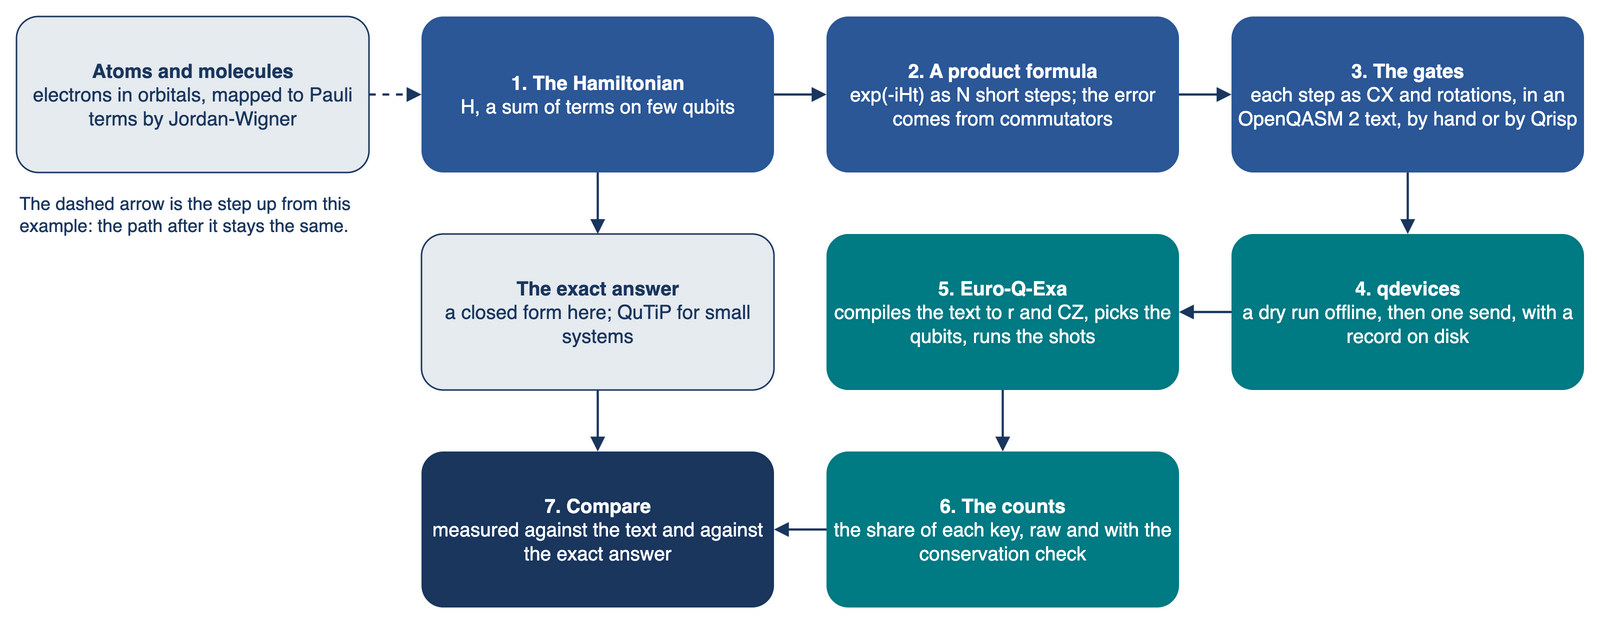

In [1]:
import importlib.util, os, sys
from pathlib import Path
from IPython.display import Image
import numpy as np

if not os.path.exists("chain.py"):
    raise SystemExit("Open this page from examples/hamiltonian/ of a clone, where its files are.")
sys.path[:0] = [os.getcwd(), os.path.abspath("../tools")]

Image("figs/pipeline.png", width=900)

## 1. The task: apply $e^{-iHt}$

The Schrödinger equation, with $\hbar = 1$, is

$$i\frac{d}{dt}|\psi(t)\rangle = H|\psi(t)\rangle .$$

For a Hamiltonian that does not depend on time, the solution is

$$|\psi(t)\rangle = e^{-iHt}|\psi(0)\rangle .$$

In the eigenbasis of $H$, with $H|E_k\rangle = E_k|E_k\rangle$, each component only gains a phase:

$$|\psi(t)\rangle = \sum_k c_k\, e^{-iE_k t}\, |E_k\rangle .$$

The dynamics come from differences of energies. And the energies are written in phases.

For $n$ qubits, $H$ is a matrix of size $2^n \times 2^n$. A gate-based quantum computer such as Euro-Q-Exa does not apply such a matrix directly: it offers one-qubit and two-qubit gates. The task is possible when $H$ is a sum of terms that each act on few orbitals or spins, $H = \sum_j H_j$, as the Hamiltonians here are, because the exponential of each term is a short circuit. So we build $e^{-iHt}$ from those short circuits (Lloyd).

## 2. The model, and its exact answer

Three qubits in a line, with

$$H = \frac12\sum_{k=0}^{1}\left(X_k X_{k+1} + Y_k Y_{k+1}\right).$$

Call a qubit in $|1\rangle$ an excitation. One term moves an excitation to the neighbouring qubit, and gives zero on $|00\rangle$ and $|11\rangle$:

$$\tfrac12(XX+YY)\,|01\rangle = |10\rangle .$$

So the number of excitations never changes. With one excitation the state lives in three dimensions, and there $H$ is

$$\begin{pmatrix}0&1&0\\1&0&1\\0&1&0\end{pmatrix}, \quad\text{with eigenvalues } 0, \pm\sqrt2 .$$

Expand the start in the eigenvectors $(1,\sqrt2,1)/2$, $(1,-\sqrt2,1)/2$ and $(1,0,-1)/\sqrt2$, with $E=\sqrt2,-\sqrt2,0$. The start $(1,0,0)$, the excitation on `q[0]`, has components $\tfrac12,\tfrac12,\tfrac1{\sqrt2}$. Each gains its phase, as in Section 1. Adding them gives the amplitudes $\cos^2\frac{t}{\sqrt2}$, $-\frac{i}{\sqrt2}\sin(\sqrt2t)$, $-\sin^2\frac{t}{\sqrt2}$ on `q[0]`, `q[1]`, `q[2]`.

The share of each outcome is the square of its amplitude. A key reads `q[2] q[1] q[0]`, as the machine returns it:

$$P_{001}(t)=\cos^4\frac{t}{\sqrt2},\qquad P_{010}(t)=\tfrac12\sin^2(\sqrt2\,t),\qquad P_{100}(t)=\sin^4\frac{t}{\sqrt2}.$$

At $T=\pi/\sqrt2$ the phases $e^{\mp i\sqrt2T}$ are both $-1$, so the state is $-|100\rangle$: the excitation is on `q[2]` in full. At $2T$ it is back on `q[0]`. Chains of equal couplings do this exactly only at two and three qubits (Christandl et al.). Below, the same numbers come from three routes: the closed form, a matrix exponential, and QuTiP's solver of the Schrödinger equation.

In [2]:
from chain import T, closed_form
from matrices import H
from tables import routes

print(f"T = {T:.4f}; the eigenvalues of H: {np.round(np.linalg.eigvalsh(H), 4)}")
print(routes())

if importlib.util.find_spec("qutip"):
    %run exact.py
else:
    print("QuTiP is not installed here, so its check is left out.")

T = 2.2214; the eigenvalues of H: [-1.4142 -1.4142 -0.     -0.      0.      0.      1.4142  1.4142]
   t  closed form 001, 010, 100     matrix exponential
   0  1.000 0.000 0.000           1.000 0.000 0.000
 T/2  0.250 0.500 0.250           0.250 0.500 0.250
   T  0.000 0.000 1.000           0.000 0.000 1.000
  2T  1.000 0.000 0.000           1.000 0.000 0.000


    t      sesolve 001, 010, 100                closed form
    0   1.0000   0.0000   0.0000   1.0000   0.0000   0.0000
  T/4   0.7286   0.2500   0.0214   0.7286   0.2500   0.0214
  T/2   0.2500   0.5000   0.2500   0.2500   0.5000   0.2500
 3T/4   0.0214   0.2500   0.7286   0.0214   0.2500   0.7286
    T   0.0000   0.0000   1.0000   0.0000   0.0000   1.0000
   2T   1.0000   0.0000   0.0000   1.0000   0.0000   0.0000
largest difference: 1.1e-11


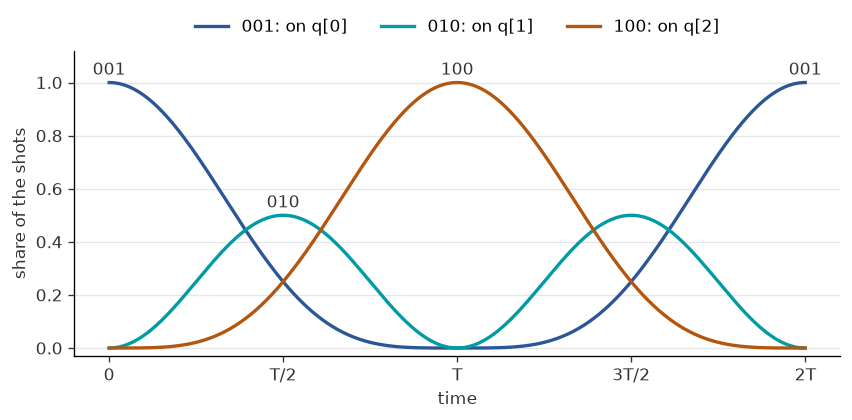

In [3]:
from figures import curves
curves();

## 3. Split the exponential: product formulas

Write $H = A + B$, with $A$ on `q[0], q[1]` and $B$ on `q[1], q[2]`. Each part is easy: a short circuit (Section 4). But they do not commute, $[A,B]\neq 0$, so $e^{-i(A+B)t} \neq e^{-iBt}e^{-iAt}$.

For a short time $dt=t/N$ the difference is small, and that is the idea of a product formula. $N$ steps of

- **order 1:** $U_1(dt) = e^{-iB\,dt}\,e^{-iA\,dt}$, with an error of order $dt^2$ a step;
- **order 2:** $U_2(dt) = e^{-iA\,dt/2}\,e^{-iB\,dt}\,e^{-iA\,dt/2}$, with an error of order $dt^3$ a step.

These are also called Trotter steps. Expanding gives $U_1(dt)=e^{-iH\,dt}+\tfrac12[A,B]\,dt^2+O(dt^3)$, so the commutator sets the first error; the symmetric form of order 2 cancels it. A product acts from the right, so in $U_1$ $A$ acts first.

Over $N$ steps the errors add at most, so the total falls as $1/N$ at order 1 and as $1/N^2$ at order 2 (Suzuki). Its size is bounded by the commutators of the terms: pairs at order 1, nested commutators at higher orders. Terms that commute add nothing, so the number of terms alone does not set it (Childs et al.). The bound is for the worst state; a given state can do better.

The table gives the largest error on any state, $\lVert V - e^{-iHT}\rVert$, the share of the arrival key, and the two-qubit gates each circuit needs.

In [4]:
from tables import formulas

print(formulas())

  N | error, order 1, order 2 | share of 100, order 1, order 2 | two-qubit gates, order 1, order 2
  1 |        1.6534    0.8074 |               0.4009    0.5083 |                       4         6
  2 |        0.8074    0.1829 |               0.7591    0.9704 |                       8        10
  4 |        0.3957    0.0441 |               0.9310    0.9983 |                      16        18
  8 |        0.1967    0.0109 |               0.9817    0.9999 |                      32        34
 16 |        0.0982    0.0027 |               0.9953    1.0000 |                      64        66


Doubling $N$ halves the error of order 1 and cuts that of order 2 by four. On paper, more steps are always better. But the two-qubit gates grow with $N$, and each of them adds an error on a real machine. Section 6 shows which of the two wins.

## 4. One bond as gates

We need $e^{-i\frac{\theta}{2}(XX+YY)}$. Here $R_x(\theta)=e^{-i\theta X/2}$, $R_z(\theta)=e^{-i\theta Z/2}$, and CX flips its second qubit when its first is 1. With $A=\tfrac12(XX+YY)$ the bond is $e^{-iA\theta}$, so $\theta$ is the time of that step: $dt$ or $dt/2$. $XX$ and $YY$ commute, so no further split is needed. Two identities do the rest.

1. A CX moves a Pauli operator from one qubit to two: $\mathrm{CX}(X\otimes I)\mathrm{CX} = X\otimes X$ and $\mathrm{CX}(I\otimes Z)\mathrm{CX} = Z\otimes Z$. So `cx a,b; rx(θ) a; rz(θ) b; cx a,b` is $e^{-i\frac{\theta}{2}(XX+ZZ)}$.
2. A rotation changes the basis: $R_x(-\tfrac{\pi}{2})\, Z\, R_x(\tfrac{\pi}{2}) = Y$, and $X$ stays $X$. So with $R_x(\pi/2)$ on both qubits before and $R_x(-\pi/2)$ after, $ZZ$ becomes $YY$.

That is 2 CX for a bond. Neighbouring $R_x(\pi/2)$ and $R_x(-\pi/2)$ cancel, so a whole job needs them only at its two ends. The figure shows the job, one bond, and the general recipe for any Pauli term. The cell checks the bond against the matrix exponential.

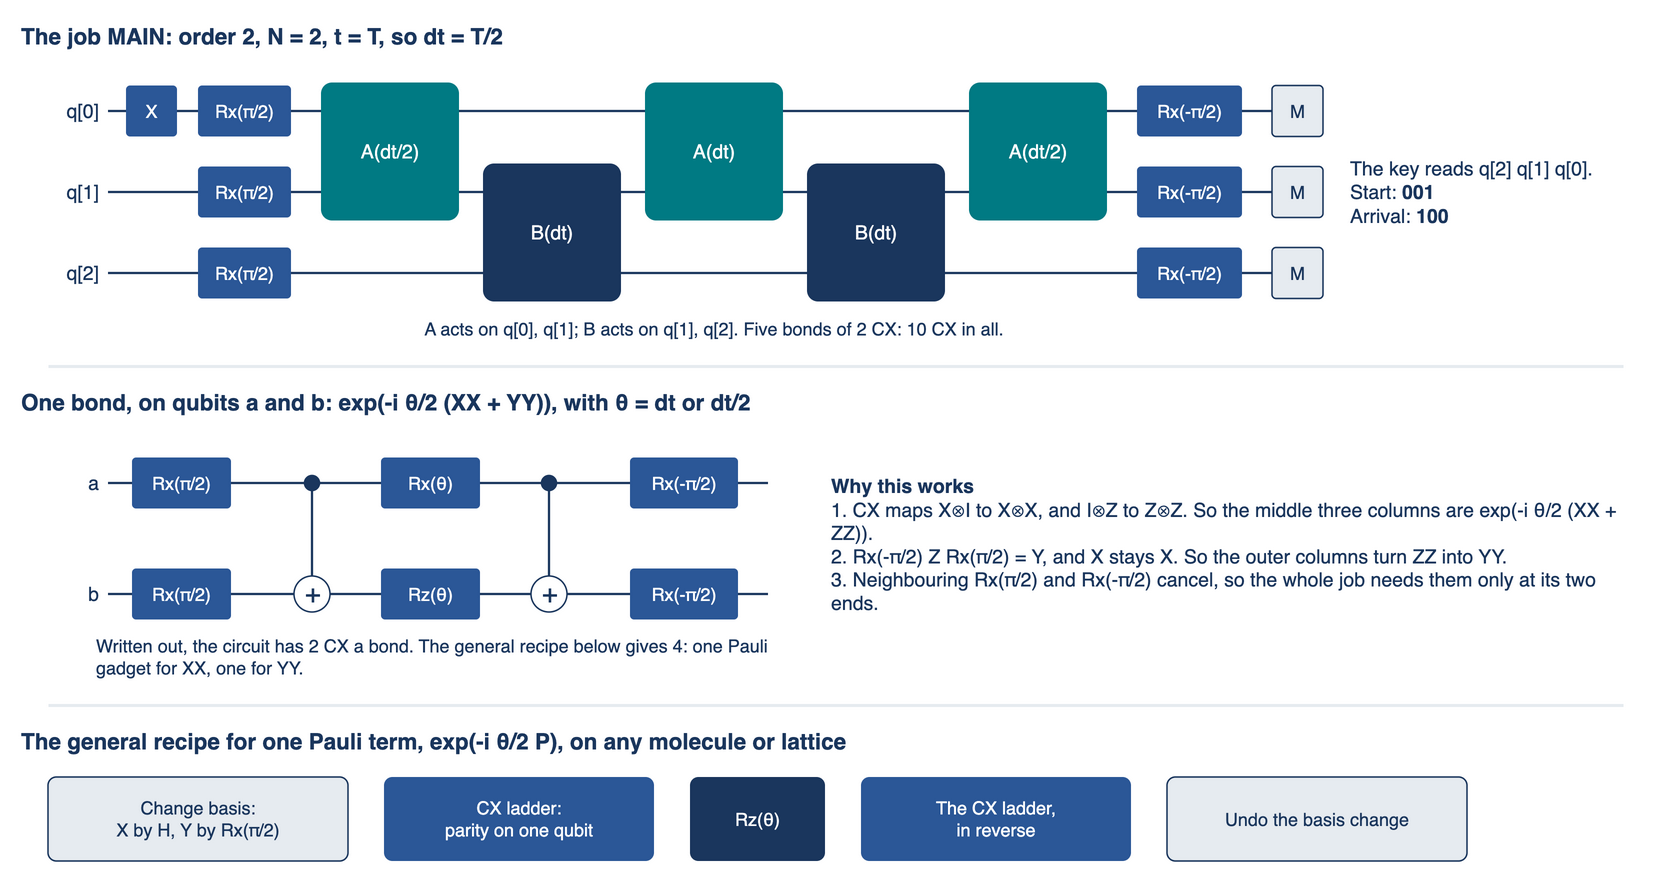

In [5]:
Image("figs/circuit.png", width=900)

In [6]:
from scipy.linalg import expm
from matrices import bond, pauli

theta = 0.7
wanted = expm(-0.5j * theta * (pauli("XX") + pauli("YY")))
print("largest difference from the exponential:", float(np.abs(bond(theta) - wanted).max()))

largest difference from the exponential: 1.1902799230898936e-16


## 5. The whole circuit, in two forms

**Written bond by bond.** `chain.py` writes the text the machine gets: OpenQASM 2, a gate-level text that the site compiles. Here is the main job, MAIN: order 2, $N=2$, $t=T$.

In [7]:
from chain import Steps
from circuit import Circuit
from emulate import fractions, top

text = Steps(T, 2).text()
circuit = Circuit.of_text(text)
print(text)
print(circuit.size)
print("A perfect machine:", top(circuit.shares()))

OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
creg c[3];
x q[0];
rx(1.5707963267948966) q[0];
rx(1.5707963267948966) q[1];
rx(1.5707963267948966) q[2];
cx q[0],q[1];
rx(0.5553603672697958) q[0];
rz(0.5553603672697958) q[1];
cx q[0],q[1];
cx q[1],q[2];
rx(1.1107207345395915) q[1];
rz(1.1107207345395915) q[2];
cx q[1],q[2];
cx q[0],q[1];
rx(1.1107207345395915) q[0];
rz(1.1107207345395915) q[1];
cx q[0],q[1];
cx q[1],q[2];
rx(1.1107207345395915) q[1];
rz(1.1107207345395915) q[2];
cx q[1],q[2];
cx q[0],q[1];
rx(0.5553603672697958) q[0];
rz(0.5553603672697958) q[1];
cx q[0],q[1];
rx(-1.5707963267948966) q[0];
rx(-1.5707963267948966) q[1];
rx(-1.5707963267948966) q[2];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];

qubits read 3, gates 27, two-qubit gates 10
A perfect machine: 100: 0.970  001: 0.027  010: 0.003


The same text as a picture, drawn by code: `qutip-qip`, the quantum information processing package of QuTiP, draws the gates as the text has them, so the gates and their order are those that are sent. One-qubit gates are blue, two-qubit gates orange; each rotation shows its angle, and the meters on the right are the three measurements. The figure of Section 4 groups the same gates into bonds.

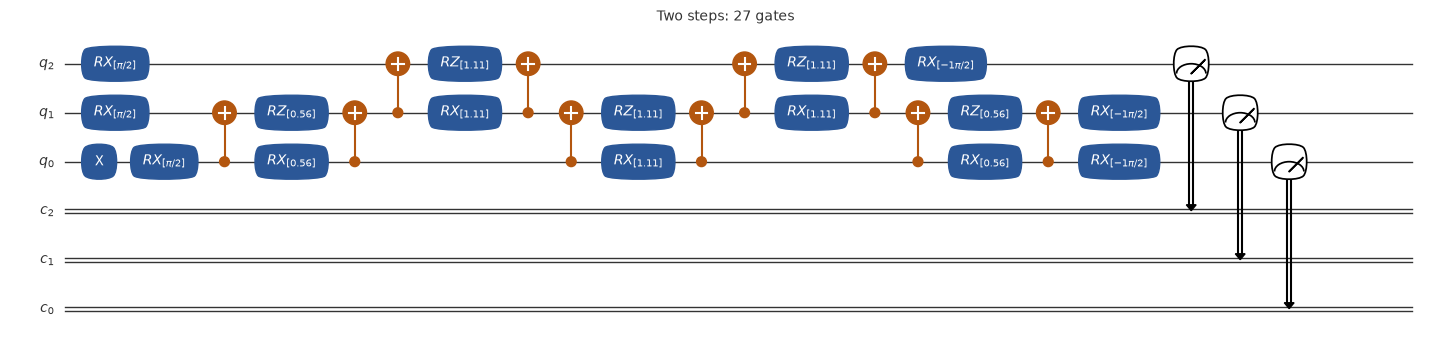

In [8]:
if importlib.util.find_spec("qutip_qip"):
    from circuit import Circuit
    from pictures import circuit_figure
    steps = Circuit.of_text(text)
    circuit_figure(steps, most=len(steps.ops), title="Two steps");
else:
    print("qutip-qip is not installed here, so this drawing is left out: pip install qutip-qip")

**In one line of Qrisp.** Qrisp's `trotterization` builds the same evolution from the operator (`with_qrisp.py`):

```python
ham = 0.5 * sum(X(k) * X(k + 1) + Y(k) * Y(k + 1) for k in range(2))
ham.trotterization(order=2, method="commuting")(qv, t=T, steps=2)
```

With `method="commuting"` it turns $XX$ and $YY$ together to diagonal form, with one CZ on each side and 2 CX in the diagonal part: 4 two-qubit gates a bond, 20 in this job. The default method writes the two gadgets of the figure, also 4 on one bond, but at order 2 not all its halves merge: 26 in this job, for the same operator. The operator is the same, so the shares are the same. Where Qrisp is installed the cell also emulates its circuit; in every case it then reads the text that was sent.

In [9]:
if importlib.util.find_spec("qrisp"):
    from with_qrisp import chain_by_qrisp, measured
    print("Qrisp's own emulator; its labels read q[0] first:", top(measured(chain_by_qrisp(T, 2))))

circuit = Circuit.of_text(Path("state_transfer/QRISP.qasm").read_text())
print(circuit.size)
print("A perfect machine:", top(circuit.shares()))

Qrisp's own emulator; its labels read q[0] first: 001: 0.970  100: 0.027  010: 0.003
qubits read 3, gates 59, two-qubit gates 20
A perfect machine: 100: 0.970  001: 0.027  010: 0.003


## 6. What came back from the machine

The eleven jobs went to Euro-Q-Exa in one run on one evening, through the app `qdevices`, each with 1000 shots (CONTROL with 100). It shows how much of each answer survived that evening, not how good the machine is. The site compiles each text to the machine's own gates, `r` and `cz`, and places it on its qubits. The record does not hold the compiled circuit, so what follows about the compile is inferred from the counts.

A shot is one run of the circuit, ended by one measurement of every qubit; its key is the bits that come back. *Readable*, as set before the run: the ideal top key is the top of the counts and at least twice the next wrong key.

`state_transfer/results.json` holds the counts. After a run of your own, `compare.py --live` writes `live.json`, and this page reads it in place of the same jobs (the README says how). To read a run sent by someone else, such as the speaker of a talk, put its link in `COUNTS`.

In [10]:
from reading import Run

COUNTS = "live.json" if Path("live.json").exists() else "state_transfer/results.json"     # or a link: https://...

run = Run.of("state_transfer", COUNTS)
print("The counts come from", COUNTS)
print(run.table())

The counts come from state_transfer/results.json
job            t  N  2q  key  perfect   read   kept  checked
CONTROL        0  0   0  001    1.000  0.970  0.970    1.000
MAIN           T  2  10  100    0.970  0.641  0.706    0.908
QRISP          T  2  20  100    0.970  0.696  0.769    0.905
REPEAT         T  2  10  100    0.970  0.661  0.741    0.892
HALF         T/2  2  10  010    0.480  0.351  0.728    0.482
BACK          2T  4  18  001    0.988  0.476  0.604    0.788
ZERO           T  2  10  000    1.000  0.642  0.642    1.000
STEPS1         T  1   6  100    0.508  0.381  0.820    0.465
STEPS4         T  4  18  100    0.998  0.474  0.572    0.829
STEPS8         T  8  34  100    1.000  0.190  0.388    0.490
ORDER1         T  2   8  100    0.759  0.638  0.805    0.793


Read the table from the top. *perfect* is what a perfect machine gives for that text. *read* is the share of all shots. *kept* and *checked* come from the conservation check below.

**CONTROL** has no evolution: only the X gate and the readout. It reads `001`, so q[0] is the right-hand character of a key. A reversed reading would look like no transfer at all.

**MAIN** is the job of Section 5, and the result this tutorial is built on. The excitation arrives: `100` is the top key by far. The perfect share is 0.970, so most of the loss is the machine's, not the formula's.

**REPEAT** is the same text as MAIN, sent again about 12 seconds later. One number from one job says little until you know how far a second job of the same circuit lands from it, so a repeat is the first check of any measurement. The two differ by 0.020. Shot noise alone, at 1000 shots each, gives a difference of about 0.021, so they agree as far as 1000 shots can show. One pair, 12 seconds apart, says nothing about how the machine drifts over minutes, hours or days. $N = 1, 4$ and $8$ ran about three minutes after $N = 2$, and no repeat spans that gap.

**The conservation check.** Every step keeps one excitation, so a key with another number of 1s is a machine error, never an error of the formula. *kept* is the share of shots that pass, and *checked* is the answer among those. The check removes one readout flip in every case. It cannot remove an error that keeps the number of excitations, such as a wrong angle on a whole bond, so it is shown beside the raw reading, never in its place. The same check is used in chemistry, where the number of electrons is conserved (Section 10).

**ZERO** is the MAIN text without the X gate. With no excitation $H|000\rangle = 0$, so a perfect machine gives `000` at any $t$ and any $N$, with no error of the formula at all. Here the answer is known exactly, so its reading shows what the compiled gates and the readout cost. It reads well below CONTROL, so gates did run. The counts do not show how many. Only `000` has no 1s, so here *checked* is 1 by construction.

**QRISP** has twice the two-qubit gates of MAIN in its text, and reads no lower (0.696 against 0.641 and 0.661). So the site's compile very likely merged gates within each bond, though the counts do not show how many ran. A text is a request, not what runs: the job page on the portal shows the circuit that ran. We have not read that page for this run. The two-spin example [`ising2`](https://github.com/ENCCS/eurohpc-qdevices/tree/main/examples/qrisp/ising2) shows this more sharply: at 5 and at 16 Trotter steps it read the same, very likely as all its steps are one two-qubit block.

**HALF and BACK** follow the excitation in time. At $T/2$ the middle key leads, and at $2T$ the start key leads again. BACK evolves forward only, so no gate meets its own inverse. A compile could still shorten it: its product is close to the identity on all eight states, as the exact evolution at $2T$ is the identity, and it equals three bonds with small angles. It reads close to STEPS4, with the same 18 two-qubit gates in its text (0.476 against 0.474, where shot noise alone gives about 0.022; kept 0.604 against 0.572). It keeps far fewer shots than STEPS1, with 6 (0.604 against 0.820), so it was very likely not cut to three bonds.

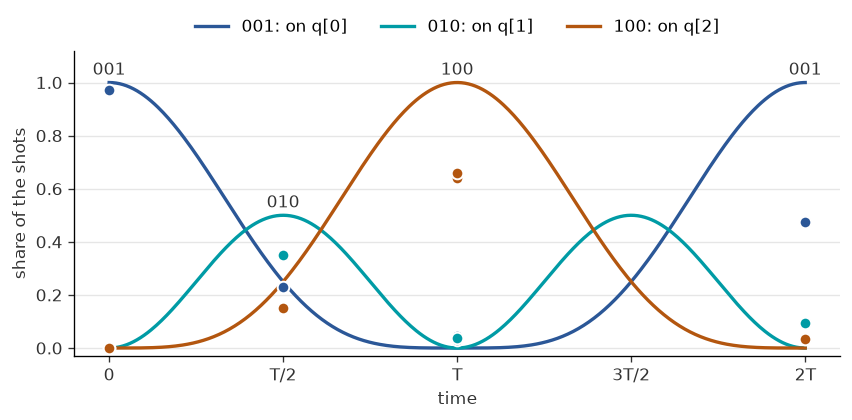

In [11]:
curves(run.over_time());

At each time the key that should lead leads, but it reads below its curve, by what the machine loses. After the gates, a key that should be empty reads above zero. The shot error of a point, at most 0.017, is smaller than its dot.

**The number of steps.** Now the same time $T$ with $N = 1, 2, 4, 8$.

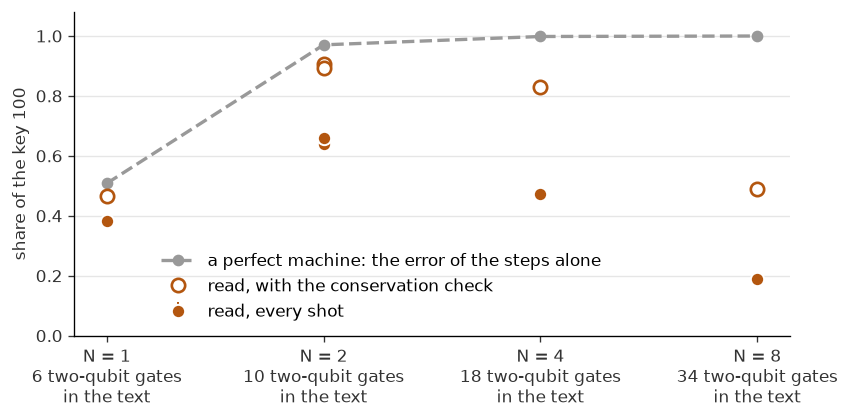

In [12]:
from figures import sweep

sweep(run.over_steps());

This is the main result. At $N=1$ the formula itself is wrong: a perfect machine gives only 0.508. At $N=2$ the formula is nearly right and the circuit is still short, and the reading is the highest of the four. At $N=4$ and $N=8$ the formula is close to perfect, but the reading falls. Each step adds gates, which fits the fall; one run cannot separate this from other causes. The best number of steps is set by both errors together. An experiment on two transmons, on the transverse-field Ising model, shows the same kind of maximum at a finite number of steps (Salathé et al.). On the same XX model, Smith et al. state the trade-off, measure the loss with each added step, and use the same conservation check.

That fall also tells us something about the compile. This model is free fermions (Section 8). For three sites every product of its bonds equals three bonds with suitable angles, at any $N$: 6 CX in all (Kökcü et al.). As the reading falls with $N$, the compile very likely did not find that form.

**Order 1 against order 2.** ORDER1 has 2 fewer two-qubit gates than MAIN, and a perfect share of 0.759 against 0.970. Raw, the two read about the same (0.638 against 0.641 and 0.661). Two fewer gates do not explain this: the simple model of Section 7, set to match MAIN, puts ORDER1 about 0.1 below it. One pair of jobs cannot say why. With the conservation check the gain of order 2 shows: 0.908 and 0.892 against 0.793. The check is not a bound: ORDER1 then reads above its perfect 0.759, by about two standard errors. Key `100` read 0.84 of its perfect share and key `010` only 0.58. The simple model of Section 7 does not do this, and one job cannot say why.

**What may be said from this.** What these compiled jobs returned, on that evening. Not what one gate costs: for that one needs the circuit that ran, and many runs.

## 7. Emulate it yourself

Now try the same jobs with no machine at all. `tools/emulate.py` runs a text on a state vector, in Python alone. Its noise is a simple model for learning: after each two-qubit gate, one of the 15 two-qubit Pauli errors with chance `noise`, and at the end each bit reads wrong with chance `readout`. It is not a model of Euro-Q-Exa. Change the numbers below.

In [13]:
# Try it: choose a time, a number of steps, and how noisy the machine is. Nothing is sent.
t, steps, order = T / 2, 3, 2
noise, readout = 0.03, 0.03

circuit = Circuit.of_text(Steps(t, steps, order).text())
print(circuit.size)
print("The exact shares: ", top(closed_form(t)))
print("A perfect machine:", top(circuit.shares()))
print("With this noise:  ", top(fractions(circuit.sample(2000, noise, readout))))

qubits read 3, gates 35, two-qubit gates 14
The exact shares:  010: 0.500  001: 0.250  100: 0.250
A perfect machine: 010: 0.491  001: 0.261  100: 0.248
With this noise:   010: 0.361  001: 0.198  100: 0.168  000: 0.086  011: 0.077  110: 0.043  and 2 more


Where Qrisp is installed, Sections 5 and 8 run its emulator. Section 9 shows a stored run of it, unless you set `RUN_THE_GATES = True`. Here it stands beside ours, beside a third emulator, QuTiP, and beside the machine, on the key of each job. QuTiP runs the same text gate by gate through its package qutip-qip, on a state vector with no noise. The cell runs each of the two if it can, and otherwise reads its stored shares: `state_transfer/qrisp_emulated.json` and `state_transfer/qutip_emulated.json`.

In [14]:
from emulate import qrisp_stored, qutip_stored

folder = Path("state_transfer")
shares = {"Qrisp": qrisp_stored(folder), "QuTiP": qutip_stored(folder)}
if importlib.util.find_spec("qrisp"):
    from qrisp_emulator import folder_shares as by_qrisp
    shares["Qrisp"] = by_qrisp(folder)
if importlib.util.find_spec("qutip_qip"):
    from qutip_emulator import folder_shares as by_qutip
    shares["QuTiP"] = by_qutip(folder)[0]
print(run.beside(shares))

job          key      ours     Qrisp     QuTiP  machine
CONTROL      001  1.000000  1.000000  1.000000    0.970
MAIN         100  0.970409  0.970410  0.970409    0.641
QRISP        100  0.970409  0.970410  0.970409    0.696
REPEAT       100  0.970409  0.970410  0.970409    0.661
HALF         010  0.480430  0.480430  0.480430    0.351
BACK         001  0.987890  0.987890  0.987890    0.476
ZERO         000  1.000000  1.000000  1.000000    0.642
STEPS1       100  0.508307  0.508310  0.508307    0.381
STEPS4       100  0.998267  0.998270  0.998267    0.474
STEPS8       100  0.999894  0.999900  0.999894    0.190
ORDER1       100  0.759056  0.759052  0.759056    0.638


Ours and Qrisp's agree to about five places: the largest difference in any key is about 0.000006 in these eleven jobs, in STEPS8, and about 0.000009 in all 43 jobs of the examples, in `qrisp/ising`. Qrisp's emulator rounds its shares to 5 or 6 places and scales them to sum to 1, and those two steps give the whole difference, to the 8 places stored. Ours and QuTiP agree to the 8 places stored: the largest difference in all 43 jobs is 0.000000005, in `qrisp/qubo`, which is that rounding, and before it 0.0000000000000014. So QuTiP and Qrisp differ by as much as ours and Qrisp's do. All three read the text through the same parser, so the comparison checks the gates and the state vector, not how a text is read. Neither the emulator Qrisp runs by default nor QuTiP as it runs here has a model of noise, so the noise in this section is ours alone. The stored files were made on an Apple Silicon Mac; on another kind of computer a live run of Qrisp may differ from its file by about 0.00001.

In [15]:
# The rise and fall, emulated: the share of 100 at T, for each number of steps, at three levels of noise.
from tables import arrival, rise_and_fall

print(rise_and_fall())

  N   2q  perfect  noise 0.01  noise 0.03  noise 0.06
  1    6    0.508       0.444       0.424       0.385
  2   10    0.970       0.818       0.689       0.545
  3   14    0.994       0.796       0.653       0.467
  4   18    0.998       0.789       0.592       0.392
  6   26    1.000       0.726       0.485       0.302
  8   34    1.000       0.671       0.408       0.236
 12   50    1.000       0.615       0.299       0.171


The table holds readout at 0.03, and each number is a sample, good to about 0.02. More noise lowers every row, and the long circuits lose the most, so the rise and fall of Section 6 appears here with no machine. Now put the emulator beside the machine.

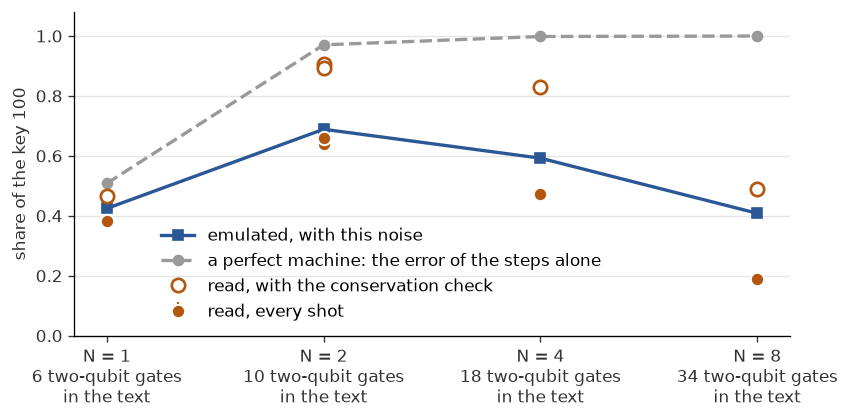

In [16]:
# Can you match the machine? The chart of Section 6, with the emulator on it. Change the two numbers and run this cell again.
noise, readout = 0.03, 0.03

rows = run.over_steps()
sweep(rows, [arrival(n, noise, readout) for n, *_ in rows]);

No one pair of numbers fits all four points. $N = 1, 2$ and $4$ alone fit to about 0.02, but with all four, $N = 8$ reads about 0.07 low, about five shot errors: from $N = 4$ to $N = 8$ the machine kept 0.40 of its share, and no pair keeps less than 0.55. That rests on one job, so it cannot say why. So one number per gate does not describe this run. Every folder of the examples can be emulated in the same way: `./emulate.sh --noise 0.03 --readout 0.03`, or the page [`all_examples.ipynb`](https://github.com/ENCCS/eurohpc-qdevices/blob/main/examples/all_examples.ipynb).

On your own laptop, with no account: `git clone https://github.com/ENCCS/eurohpc-qdevices`, `cd eurohpc-qdevices/examples/hamiltonian`, then `./open.sh` opens this page (it needs pixi), or `cd state_transfer && ./emulate.sh` runs all eleven jobs with Python alone.

To run a job on the machine you need an account of your own: a token acts fully as its owner, so it is never handed to someone else. From this page you cannot send a job, and that is on purpose. The [ENCCS lesson](https://enccs.github.io/eurohpc-quantum-devices-access-hpcqc/) says how to get an account, and the README in [`live/`](https://github.com/ENCCS/eurohpc-qdevices/tree/main/examples/hamiltonian/live) says how to send the job of a talk.

## 8. From three qubits to atoms and molecules

The path carries over; the shortcuts do not. Electrons in an atom or a molecule, with the nuclei held fixed and a finite set of spin orbitals, are described by

$$H = \sum_{pq} h_{pq}\, a_p^\dagger a_q + \frac12\sum_{pqrs} g_{pqrs}\, a_p^\dagger a_q^\dagger a_r a_s ,$$

where $a_p^\dagger$ puts an electron in spin orbital $p$. The numbers $h$ and $g$, with $g_{pqrs}=\langle pq|sr\rangle$, are integrals that a classical code computes.

With one electron, or many with no second sum, the problem stays free-fermion: an $M\times M$ matrix, which a classical computer diagonalises in time polynomial in $M$. That is why the chain has a closed form and fits 6 CX. The second sum couples the electrons. An exact classical solution then works in a space of size $\binom{M}{n}$, for $n$ electrons in $M$ spin orbitals: about $10^{29}$ for 50 in 100. $M$ qubits hold that space, which is why the method is studied. Classical methods treat many molecules well. A broad study of ground-state energies found no evidence so far of an exponential quantum gain across chemical space, and calls a relevant system with strong evidence an open question. It did not study other tasks and does not rule out smaller gains (S. Lee et al.).

**Step 1, to qubits.** Let qubit $p$ read 1 when spin orbital $p$ is full. The Jordan-Wigner transformation writes $a_p = \left(\prod_{k<p} Z_k\right)\tfrac12(X_p + iY_p)$. Electrons anticommute, $a_pa_q=-a_qa_p$. Operators on different qubits commute, so the $Z$ string supplies the sign: it counts, modulo 2, the electrons in the orbitals below $p$. So a term can reach across many qubits. For neighbouring orbitals the $Z$s cancel:

$$a_k^\dagger a_{k+1} + a_{k+1}^\dagger a_k = \tfrac12\left(X_k X_{k+1} + Y_k Y_{k+1}\right).$$

**That is the bond of this tutorial.** The chain above is one electron hopping along three orbitals in a line. Its $3\times3$ matrix is the Hückel matrix of the three π orbitals of the allyl radical, in units of $\beta$, with $\alpha$ set to zero. The radical has three π electrons; here we follow one, and with no second sum each moves on its own. Between orbitals that are not neighbours, the $Z$s stay. The cell checks both.

In [17]:
from matrices import JordanWigner

two, three = JordanWigner(2), JordanWigner(3)
print("hop(0, 1) = (XX + YY)/2 on two orbitals:", np.allclose(two.hop(0, 1), 0.5 * (pauli("XX") + pauli("YY"))))
print("hop(0, 1) + hop(1, 2) = H of this tutorial:", np.allclose(three.hop(0, 1) + three.hop(1, 2), H))
print("hop(0, 2) = (XZX + YZY)/2, a Z stays between:", np.allclose(three.hop(0, 2), 0.5 * (pauli("XZX") + pauli("YZY"))))

hop(0, 1) = (XX + YY)/2 on two orbitals: True
hop(0, 1) + hop(1, 2) = H of this tutorial: True
hop(0, 2) = (XZX + YZY)/2, a Z stays between: True


**Step 2, the terms.** The second sum of $H$ adds terms such as $Z_pZ_q$ and $X_pX_qY_rY_s$. Their number grows as the fourth power of the number of spin orbitals. Each is one Pauli term, so each uses the general recipe of the figure, and they are split by the same product formulas, with the same trade-off of Section 6.

**Step 3, what we get from it.**

- *Dynamics:* evolve a prepared state and measure, as here: how charge moves, or how a system answers a sudden change.
- *Energies:* phase estimation runs a controlled $e^{-iHt}$ and reads the phase $e^{-iEt}$ of Section 1 into a register, which gives the energy $E$ (Abrams and Lloyd; Aspuru-Guzik et al.). An error in $e^{-iHt}$ becomes an error in $E$. It returns $E_k$ with probability $|c_k|^2$, the $c_k$ of Section 1. So the state prepared first must overlap the state wanted; for a large molecule that is a problem of its own.
- *Other algorithms* use it as a part: linear systems, thermal states, adiabatic state preparation. Card [P06](https://elhamkashefi.github.io/primitives-atlas/#P06) of the Quantum Algorithmic Primitives Atlas lists them. The Quantum Algorithm Zoo (Jordan) has an entry on this routine, which lists Qrisp among its implementations.

Here is the hydrogen molecule, emulated, with the two-qubit Hamiltonian of Qrisp's [ground-state page](https://qrisp.eu/reference/Examples/GroundStateEnergyQPE.html): the same `trotterization`, inside phase estimation. Its numbers match H2 in the minimal basis STO-3G at 0.735 Å: 4 spin orbitals, which its symmetries reduce to 2 qubits. Energies are in hartree, for the electrons alone. The repulsion of the nuclei adds 0.720, so the total is -1.137.

The code is in `with_qrisp.py`, and its centre is one line:

```python
return QPE(qv, ham.trotterization(), precision=bits, kwargs={"steps": STEPS}, iter_spec=True)
```

Here `ham` is `h2()`, the numbers of the page, and `STEPS` is 3. Its start, `x(qv[0])`, is the restricted Hartree-Fock state, with energy -1.837 and squared overlap 0.988 with the ground state. At $t=1$ the register holds $\varphi$ with $e^{-iE}=e^{2\pi i\varphi}$, so $E=-2\pi\varphi$, for $E$ between $-2\pi$ and 0. The code uses the first-order formula with 3 steps per unit time: at $t=1$, 3 steps shift $E$ by 0.0005 hartree and 1 step by 0.0044. With no Qrisp the cell prints what a run gave.

The exact energy: -1.857 hartree
bits  qubits  two-qubit gates  top phase  energy
   3       5              261     0.2500  -1.571
   4       6              558     0.3125  -1.963
   5       7             1142     0.2812  -1.767
   6       8             2307     0.2969  -1.865


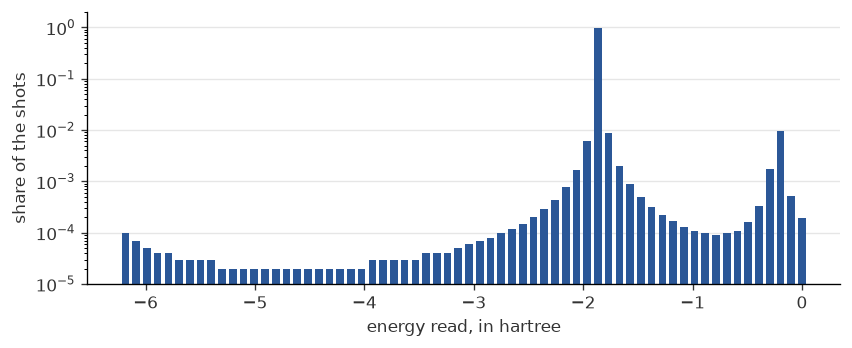

In [18]:
from figures import phases
from hydrogen import MADE

if importlib.util.find_spec("qrisp"):
    from with_qrisp import hydrogen
    estimates = hydrogen()
else:
    print("Qrisp is not installed here: this is what a run gave.")
    estimates = MADE
print(estimates.table())
phases(estimates.energies);

The chart is the last row, at 6 bits. The high bar is the grid point nearest the ground level, -1.857: the grid has steps of 0.098. The low bar near -0.2 is the upper level, -0.225, with a squared overlap of 0.012 with the start. So the chart shows both the grid and the $|c_k|^2$ above.

Each bit adds one binary digit to the phase, and about doubles the circuit, as bit $k$ runs $e^{-iH2^k}$. With 6 bits the grid of $E$ has steps of $2\pi/64=0.098$ hartree. The usual target, called chemical accuracy, is about 0.0016 hartree, 1 kcal/mol, for energy differences. A grid with steps of that size takes 12 bits, about 150,000 two-qubit gates in this form, with no compression. In the run above the answer was clear at 18 two-qubit gates in the text (474 against 108) and no longer readable at 34 (190 against 175, where the rule asks for twice). That gap is what this small example measures.

## 9. The whole curve of H2

So far the molecule has one bond length. Now we hold the nuclei fixed at many bond lengths, and compute the energy at each. The result, energy against bond length, is the potential energy curve, the picture chemists recognise for a bond. Its minimum gives the equilibrium length of the bond. The depth of its well is close to the energy it takes to break the bond, but larger by the zero-point vibration of the nuclei, which fixed nuclei leave out: about 6 kcal/mol for H2 (from the constants of the NIST WebBook). Its far end must reach the energy of two separate atoms, and not every method gets there.

The phase estimation below is emulated: a laptop computes what a perfect quantum computer would do, and nothing is sent to a machine. Its circuits are far longer than anything the machine of Section 6 read: 9248 two-qubit gates at each bond length in this form, against at most 34 in the texts sent there. A laptop also solves this molecule directly, and much faster, so nothing on this page gains over a classical computer.

**What *exact* means for each method.** Each one works on the same equation: the Schrödinger equation of the electrons, with the nuclei held fixed (the Born-Oppenheimer approximation) and no relativity. They differ in the method and in the basis. A *basis* is the finite set of functions, centred on the nuclei, from which the orbitals are built. STO-3G is a minimal basis: one function on each atom, a fixed sum of 3 Gaussians. cc-pVQZ, the largest here, has 30 on each atom.

- *Restricted Hartree-Fock* puts both electrons in one orbital. It is the start of our phase estimation. In any basis it is an approximation.
- *Full configuration interaction (FCI)* solves the Schrödinger equation exactly within a basis: in the words of Szabo and Ostlund (p. 234), "exact within the subspace spanned by the one-electron basis". So each basis has its own FCI energy. In STO-3G, for the ground state, FCI comes down to a $2\times2$ matrix, which `molecule.py` builds with NumPy alone. `exact_chemistry.py` uses PySCF for the larger bases, and this page reads its stored numbers.
- *Phase estimation in STO-3G* reads the levels of the same $2\times2$ matrix, on a grid of energies and through a product formula. With a finer grid and more steps it closes on FCI in STO-3G, and on nothing better. A single reading can fall below FCI: that is the grid, not a better result.
- *The published values* (Pachucki) solve the same equation with no limit from a basis, as they are extrapolated to a complete set. To every digit we print they are exact for this equation, not for the real molecule, and they are computed, not measured. Here they are the benchmark. Sims and Hagstrom agree with them to better than $4\times10^{-12}$ hartree at every length both list, from 0.21 to 3.18 Å.

`Molecule(length).terms` gives the five coefficients of the two-qubit Hamiltonian at any bond length. At 0.735 Å they are the numbers on Qrisp's page, to every digit it prints, and the cell prints how close. The run is the same `trotterization` inside phase estimation as in Section 8, at 8 bits, with 3 steps per unit time, at eight bond lengths. Only the angles change with the length, so the count of gates is the same at each. The next cell shows a stored run of those gates, so Run All stays light; a fresh run on a laptop gave the same numbers. Set `RUN_THE_GATES = True` to run them yourself. On a laptop that took from half a minute to about three minutes, and about 1.5 GB of memory. The checks behind this section are in [`curve_checks.md`](https://github.com/ENCCS/eurohpc-qdevices/blob/main/examples/hamiltonian/curve_checks.md).

In [19]:
from hydrogen import Curve
from molecule import difference_from_page

RUN_THE_GATES = False       # True needs Qrisp, and about 1.5 GB of memory

print(f"Largest difference from the numbers of Qrisp's page: {max(map(abs, difference_from_page())):.1e}")
if RUN_THE_GATES:
    from with_qrisp import curve
    emulated = curve()
else:
    emulated = Curve.stored()
print(emulated.table())

Largest difference from the numbers of Qrisp's page: 4.8e-09
8 bits, 3 steps per unit time: 10 qubits, 9248 two-qubit gates, grid step 0.025 hartree
length     exact  overlap  reading  share      top  share
   0.5   -1.0552    0.995   -1.052  0.970   -1.052  0.970
0.7414   -1.1373    0.987   -1.127  0.568   -1.127  0.568
   1.1   -1.0792    0.958   -1.090  0.480   -1.090  0.480
   1.4   -1.0155    0.901   -1.021  0.749   -1.021  0.749
   1.8   -0.9618    0.777   -0.958  0.712   -0.958  0.712
   2.6   -0.9352    0.579   -0.925  0.336   -0.361  0.363
   3.0   -0.9336    0.537   -0.928  0.453   -0.928  0.453
   4.0   -0.9332    0.504   -0.923  0.280   -0.285  0.409


*length* is in Å, and all energies are total energies in hartree: the electrons and the repulsion of the nuclei, unlike the chart of Section 8. *exact* is FCI in STO-3G, and *overlap* is the squared overlap of the start with the ground state. *top* is the grid point with the most shots, and *reading* is the one that the rule below picks. Each *share* is that of the energy on its left.

**Which peak to read.** The start reaches two levels, and phase estimation returns each with its $|c_k|^2$. At 0.735 Å the overlap is 0.988, so the top reading is the ground level. As the bond stretches the overlap falls, to 0.504 at 4 Å. The start keeps both electrons in one orbital, and half of that state has both of them on one atom (the ionic terms of Szabo and Ostlund, p. 167). The ground state of two atoms far apart does not have that. So the two levels hold comparable shares, and which one is on top depends on how near each lies to a grid point.

So we read the *lowest strong peak*: the grid point with the lowest energy among those that hold at least 0.1 of the shots and no less than either neighbour. From 5 bits up this rule read the ground level at every length we tried, up to 15 Å. It uses what we know of this molecule, its overlap. For a large molecule the overlap is not known in advance.

At 2.6 angstrom: exact energy -0.935, squared overlap 0.579.
bits  top reading  lowest strong peak
   6       -0.975              -0.975
   7       -0.925              -0.925
   8       -0.361              -0.925
   9       -0.938              -0.938
  10       -0.355              -0.938


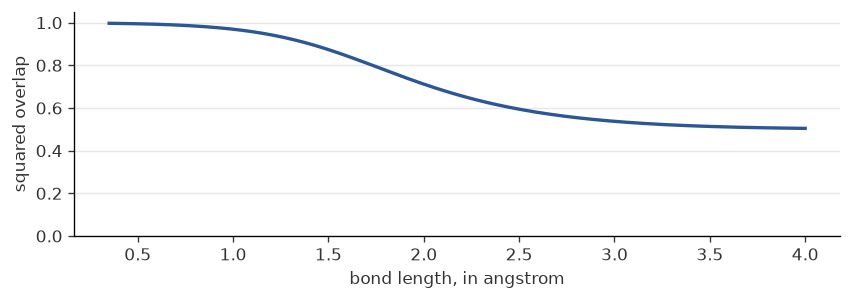

In [20]:
from figures import overlaps
from tables import readings

overlaps();
print(readings())

The chart shows the fall of the overlap. The table comes from the closed form of the shares of phase estimation (in `curve_checks.md`), with no gates and no product formula. At 2.6 Å, the length of the table, the top reading at 8 and at 10 bits is -0.361 and -0.355: that is the upper level, at -0.3558, and not the ground level, at -0.935. At 6, 7 and 9 bits it is the ground level, so more bits do not cure this. The lowest strong peak stays near the ground level at each number of bits. In the emulated curve above, the top reading is the wrong level at 2.6 Å and at 4 Å.

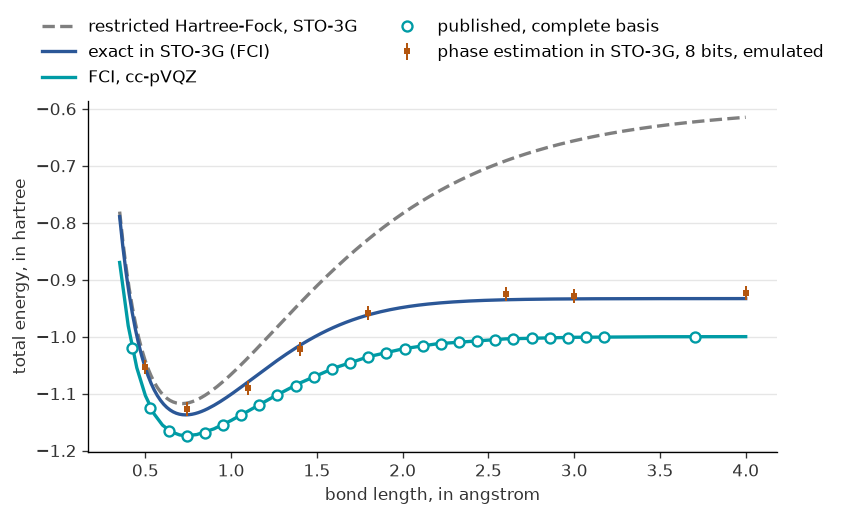

In [21]:
from figures import dissociation

dissociation(emulated);

**Reading the chart.** Each orange point has a bar of half a grid step either way.

The grey line, restricted Hartree-Fock in STO-3G, has a well but no proper far end. At 4 Å it reads -0.6149, where two atoms in this basis have -0.9332, so it lies 0.3183 too high, and it goes on rising, to 0.3873 too high at infinite distance. Szabo and Ostlund give the cause (p. 167): "since both electrons occupy the same spatial orbital, there remains even at infinity some electron-electron repulsion."

The blue line, exact in STO-3G, does reach the energy of two atoms in this basis. The orange points follow it: the largest gap is 0.0105. They fall on either side of the line, so a point below it is the grid, not a better result.

The teal line, FCI in the largest basis here, runs through the published points. The blue line lies above the published values at all 24 stored lengths, as the variational principle requires: by 0.0370 at its closest, at 0.7 Å, and by 0.0819 at 0.35 Å. In the words of Szabo and Ostlund (p. 241): "although full CI is exact in the STO-3G basis, it gives a potential curve which does not agree very well with the exact one."

A deeper well is not a better result here. The minimum of the blue curve, at 0.7349 Å against the published 0.7414 Å, lies 0.2041 below its two atoms. The well of the published curve is 0.1745 deep. So the well of STO-3G is deeper than the published one, although its energy lies above the published one at every stored length. The reason is the atom: in this basis it has -0.4666, where the exact value is -0.5 (Szabo and Ostlund, p. 161). Two atoms miss 0.0668, and the molecule at its minimum misses only 0.0372. Szabo and Ostlund (p. 241) say the well depths are greater "because the STO-3G basis is so poor for the hydrogen atom".

In [22]:
from reference import methods
from tables import well

print(methods(emulated))
print()
print(well())

                                     at 0.7414 angstrom         at 3.0 angstrom            
method                                hartree    above kcal/mol   hartree    above kcal/mol  
restricted Hartree-Fock, STO-3G       -1.1167  +0.0578   +36.3    -0.6560  +0.3453  +216.7 
exact in STO-3G: FCI                  -1.1373  +0.0372   +23.3    -0.9336  +0.0677   +42.5 
phase estimation in STO-3G, 8 bits    -1.1270  +0.0475   +29.8    -0.9281  +0.0733   +46.0 
restricted Hartree-Fock, cc-pVQZ      -1.1335  +0.0410   +25.7    -0.8333  +0.1680  +105.4 
FCI, cc-pVQZ                          -1.1738  +0.0007    +0.4    -1.0011  +0.0003    +0.2 
published, by interpolation           -1.1745                     -1.0014                  

                  length    energy   depth
exact in STO-3G   0.7349   -1.1373  0.2041
published         0.7414   -1.1745  0.1745
STO-3G is too deep by 0.0297 hartree, 18.6 kcal/mol


In the first table, *above* is the energy less the published value at that length, also given in kcal/mol. In the second, *length* and *energy* are those of the minimum, and *depth* is how far it lies below two atoms.

The first table separates two limits: the method and the basis. A large basis does not repair the method: restricted Hartree-Fock in cc-pVQZ lies 0.0410 above at 0.7414 Å and 0.1680 above at 3 Å. An exact method does not repair the basis: FCI in STO-3G lies 0.0372 and 0.0677 above. Only both together come close: FCI in cc-pVQZ lies 0.0007 and 0.0003 above. Phase estimation in STO-3G reads the same level as FCI in STO-3G, so it has the limit of the basis, and the error of its grid as well.

**Exact in a small basis is far from the published energy.** The next two tables test that. The first uses the closed form with the 3 steps, and no gates, at 0.7414 Å. The second reads the stored numbers.

In [23]:
from reference import bases
from tables import more_bits

print(more_bits())
print()
print(bases())

bits  grid step   reading  above exact in STO-3G  above published
   6    0.09817  -1.15157               -0.01430         +0.02291
   8    0.02454  -1.12702               +0.01025         +0.04745
  10    0.00614  -1.13929               -0.00202         +0.03518
  12    0.00153  -1.13623               +0.00104         +0.03825
  14    0.00038  -1.13661               +0.00066         +0.03787
  16    0.00010  -1.13680               +0.00047         +0.03767

                           FCI above the published value
                           at 0.7414 angstrom    largest on the curve
basis      M  C(M, 2)        hartree kcal/mol      hartree kcal/mol
STO-3G     4        6        0.03721    23.35      0.08188    51.38
6-31G      8       28        0.02279    14.30      0.03545    22.25
cc-pVDZ   20      190        0.01106     6.94      0.04933    30.95
cc-pVTZ   56     1540        0.00214     1.34      0.00671     4.21
cc-pVQZ  120     7140        0.00068     0.43      0.00137     0.86


With more bits the reading closes on the exact energy in STO-3G, not on the published one. At 16 bits it lies 0.00047 above the exact energy in STO-3G, which is the shift of the 3 steps, and 0.03767 above the published one. More steps would shrink the 0.00047. No number of bits or steps touches the 0.03721 that FCI in STO-3G lies above the published value: here that takes a larger basis.

A larger basis has a price. *M* is the number of spin orbitals, which is the number of qubits before any symmetry: from 4 to 120 here. Of these five bases, only cc-pVQZ lies within 1 kcal/mol of the published values: 0.43 kcal/mol above at 0.7414 Å, and 0.86 above at its worst, at 0.35 Å. cc-pVTZ, with 56 spin orbitals, lies 1.34 above at 0.7414 Å. A larger basis is also not always lower: from 6-31G to cc-pVDZ the FCI energy rises at short bonds, by 0.0139 at 0.35 Å. Neither set contains the other, so the variational principle does not order them.

These are errors of total energies. *Chemical accuracy* usually refers to energy differences against experiment, within 1 kcal/mol (Motta and Rice). Agreement with FCI in a fixed basis is another thing, which Motta and Rice call algorithmic accuracy. Phase estimation in STO-3G could reach that and still lie about 23 kcal/mol from the published energy at 0.7414 Å.

For a classical computer these two electrons stay easy. *C(M, 2)* is the $\binom{M}{n}$ of Section 8 for two electrons, at most 7140 here, before symmetry makes it smaller: in STO-3G the 6 states become the $2\times2$ matrix. PySCF solved all five bases at all 24 bond lengths on one laptop in one to five minutes. This molecule is a place to check the method against known numbers.

Experiments have traced the curve of this molecule in a minimal basis. Lanyon et al. worked in STO-3G, with 2 photonic qubits and 20 bits of iterative phase estimation, which reads one bit at a time on one control qubit. A problem this small let them set each power of the evolution directly, "by re-encoding the same number of gates". They do not expect that for larger molecules. They also encode "exact eigenstates, obtained via a preliminary calculation on a classical computer". O'Malley et al. worked in STO-6G, with 2 superconducting qubits for a variational method and 3 for Trotterised iterative phase estimation. They write: "we are able to implement only a single Trotter step, which is not enough to achieve chemical accuracy." Their chemical accuracy is measured against the exact energy in that basis, which is the algorithmic accuracy above. So the limit of the basis applies to both.

## 10. What changes with size

| | The chain of Sections 2 to 7 | A large molecule, at useful accuracy |
|---|---|---|
| Qubits | 3 | one per spin orbital, less a few by symmetry |
| The terms | 4 Pauli terms | of order $M^4$ for $M$ spin orbitals |
| Gates of one term | 2 CX a bond | up to $2(M-1)$ CX: its $Z$ string sets the ladder |
| The start | one excitation, known exactly | a state with enough overlap with the state wanted |
| The formula | a product formula, no extra qubits | product formulas, or qubitization, whose query cost is optimal in the time and the error, at the cost of extra qubits and control (Low and Chuang) |
| The machine's errors | seen in the counts, on one evening | more than a noisy machine carries: error correction. One estimate is about four million physical qubits and under four days for an active-space model of FeMoco, at 0.1% gate error and 1 microsecond cycles (J. Lee et al.) |
| The check | the number of excitations | the number of electrons and the spin, or their parities: symmetry verification (Bonet-Monroig et al.; McArdle et al.) |
| What was sent is not what ran | the compile very likely merged gates | the same, and more: compile, routing and layout decide the cost |

So today this is a place to learn the method and to measure what a machine does with it: it reaches no answer that a classical computer cannot give. The mapping carries over to a larger, error-corrected machine. So does the split, as long as a product formula stays; on such a machine qubitization may replace it. The symmetry checks cited here were made for near-term machines.

**The same in the language of the atlas.** Card P06 describes Hamiltonian simulation by a contract in five places and a verification hook, which this tutorial fills in like this:

| | Here |
|---|---|
| Access | a list of Pauli terms |
| Promise | $H$ splits into parts that are easy to exponentiate |
| Output | $V$ applied to a state, with $V \approx e^{-iHT}$ |
| Error | $\lVert V - e^{-iHT}\rVert$: the table of Section 3 |
| Cost | 10 two-qubit gates at $N=2$, no extra qubits |
| How to check it | a conserved quantity (*kept*), a known input (ZERO), and a forward evolution that returns to its start (BACK), in place of the card's forwards-and-backwards echo test |

## References

- S. Lloyd, *Universal quantum simulators*, Science 273, 1073, [doi:10.1126/science.273.5278.1073](https://doi.org/10.1126/science.273.5278.1073).
- M. Suzuki, *General theory of fractal path integrals with applications to many-body theories and statistical physics*, J. Math. Phys. 32, 400, [doi:10.1063/1.529425](https://doi.org/10.1063/1.529425).
- A. M. Childs, Y. Su, M. C. Tran, N. Wiebe, S. Zhu, *Theory of Trotter error with commutator scaling*, Phys. Rev. X 11, 011020, [arXiv:1912.08854](https://arxiv.org/abs/1912.08854).
- M. Christandl, N. Datta, A. Ekert, A. J. Landahl, *Perfect state transfer in quantum spin networks*, Phys. Rev. Lett. 92, 187902, [arXiv:quant-ph/0309131](https://arxiv.org/abs/quant-ph/0309131).
- Y. Salathé et al., *Digital quantum simulation of spin models with circuit quantum electrodynamics*, Phys. Rev. X 5, 021027, [arXiv:1502.06778](https://arxiv.org/abs/1502.06778).
- A. Smith, M. S. Kim, F. Pollmann, J. Knolle, *Simulating quantum many-body dynamics on a current digital quantum computer*, npj Quantum Inf. 5, 106, [arXiv:1906.06343](https://arxiv.org/abs/1906.06343).
- E. Kökcü, D. Camps, L. Bassman Oftelie, J. K. Freericks, W. A. de Jong, R. Van Beeumen, A. F. Kemper, *Algebraic compression of quantum circuits for Hamiltonian evolution*, Phys. Rev. A 105, 032420, [arXiv:2108.03282](https://arxiv.org/abs/2108.03282).
- D. S. Abrams, S. Lloyd, *Quantum algorithm providing exponential speed increase for finding eigenvalues and eigenvectors*, Phys. Rev. Lett. 83, 5162, [arXiv:quant-ph/9807070](https://arxiv.org/abs/quant-ph/9807070).
- A. Aspuru-Guzik, A. D. Dutoi, P. J. Love, M. Head-Gordon, *Simulated quantum computation of molecular energies*, Science 309, 1704, [arXiv:quant-ph/0604193](https://arxiv.org/abs/quant-ph/0604193).
- G. H. Low, I. L. Chuang, *Hamiltonian simulation by qubitization*, Quantum 3, 163, [arXiv:1610.06546](https://arxiv.org/abs/1610.06546).
- J. Lee et al., *Even more efficient quantum computations of chemistry through tensor hypercontraction*, PRX Quantum 2, 030305, [arXiv:2011.03494](https://arxiv.org/abs/2011.03494).
- S. Lee et al., Nat. Commun. 14, 1952, [arXiv:2208.02199](https://arxiv.org/abs/2208.02199).
- X. Bonet-Monroig, R. Sagastizabal, M. Singh, T. E. O'Brien, *Low-cost error mitigation by symmetry verification*, Phys. Rev. A 98, 062339, [arXiv:1807.10050](https://arxiv.org/abs/1807.10050).
- S. McArdle, X. Yuan, S. Benjamin, *Error-mitigated digital quantum simulation*, Phys. Rev. Lett. 122, 180501, [arXiv:1807.02467](https://arxiv.org/abs/1807.02467).
- K. Pachucki, *Born-Oppenheimer potential for H2*, Phys. Rev. A 82, 032509, [arXiv:1007.0322](https://arxiv.org/abs/1007.0322).
- J. S. Sims, S. A. Hagstrom, *High precision variational calculations for the Born-Oppenheimer energies of the ground state of the hydrogen molecule*, J. Chem. Phys. 124, 094101, [doi:10.1063/1.2173250](https://doi.org/10.1063/1.2173250).
- A. Szabo, N. S. Ostlund, *Modern Quantum Chemistry* (Dover), pp. 161, 167, 234, 241.
- NIST Chemistry WebBook, *Hydrogen*, [constants of diatomic molecules](https://webbook.nist.gov/cgi/cbook.cgi?ID=C1333740&Mask=1000).
- M. Motta, J. E. Rice, *Emerging quantum computing algorithms for quantum chemistry*, WIREs Comput. Mol. Sci. e1580, [arXiv:2109.02873](https://arxiv.org/abs/2109.02873).
- B. P. Lanyon et al., *Towards quantum chemistry on a quantum computer*, Nature Chemistry 2, 106, [arXiv:0905.0887](https://arxiv.org/abs/0905.0887).
- P. J. J. O'Malley et al., *Scalable quantum simulation of molecular energies*, Phys. Rev. X 6, 031007, [arXiv:1512.06860](https://arxiv.org/abs/1512.06860).
- E. Kashefi (ed.), [*Quantum Algorithmic Primitives Atlas*](https://elhamkashefi.github.io/primitives-atlas/), version 0.4, card P06, CC BY 4.0.
- S. P. Jordan, [*Quantum Algorithm Zoo*](https://quantumalgorithmzoo.org/) ([source](https://github.com/stephenjordan/stephenjordan.github.io)), entry *Simulating Quantum Hamiltonian Dynamics*, which lists [Qrisp](https://qrisp.eu/general/tutorial/H2.html) among its implementations.
- Tools: [QuTiP](https://qutip.org) ([arXiv:2412.04705](https://arxiv.org/abs/2412.04705)), [qutip-qip](https://qutip-qip.readthedocs.io) ([arXiv:2105.09902](https://arxiv.org/abs/2105.09902)), [Qrisp](https://qrisp.eu) ([arXiv:2406.14792](https://arxiv.org/abs/2406.14792)), [PySCF](https://pyscf.org) (Q. Sun et al., J. Chem. Phys. 153, 024109, [arXiv:2002.12531](https://arxiv.org/abs/2002.12531)).